## 1. Libraries import

In [ ]:
import pandas as pd 
import numpy as np 

import os

import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

import functions as fpf

# ML libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
    average_precision_score, PrecisionRecallDisplay,
)

## 2. Data load

In [895]:
df = pd.read_csv('./data/churn_all.csv')

## 3. Initial exploration

In [896]:
# basic data exploration
fpf.basic_exploration(df)

What is the shape (dimensions) of the dataframe?


'The dataframe has 5000 rows and 20 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,state,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,Churn
0,KS,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many unique values does each column have?


Churn                               2
international_plan                  2
voice_mail_plan                     2
area_code                           3
number_customer_service_calls      10
total_intl_calls                   21
number_vmail_messages              48
state                              51
total_day_calls                   124
total_eve_calls                   126
total_night_calls                 131
total_intl_minutes                170
total_intl_charge                 170
total_night_charge               1028
total_eve_charge                 1659
total_night_minutes              1853
total_eve_minutes                1879
total_day_charge                 1961
total_day_minutes                1961
phone_number                     5000
dtype: int64

----------------------------------------------------------------------------------------------------
What are the unique values of each column?


,0
state,"[KS, OH, NJ, OK, AL, MA, MO, LA, WV, IN, RI, I..."
area_code,"[415, 408, 510]"
phone_number,"[ 382-4657, 371-7191, 358-1921, 375-9999, ..."
international_plan,"[ no, yes]"
voice_mail_plan,"[ yes, no]"
number_vmail_messages,"[25, 26, 0, 24, 37, 27, 33, 39, 30, 41, 28, 34..."
total_day_minutes,"[265.1, 161.6, 243.4, 299.4, 166.7, 223.4, 218..."
total_day_calls,"[110, 123, 114, 71, 113, 98, 88, 79, 97, 84, 1..."
total_day_charge,"[45.07, 27.47, 41.38, 50.9, 28.34, 37.98, 37.0..."
total_eve_minutes,"[197.4, 195.5, 121.2, 61.9, 148.3, 220.6, 348...."


----------------------------------------------------------------------------------------------------


How many null values does each column have?


state                            0
area_code                        0
number_customer_service_calls    0
total_intl_charge                0
total_intl_calls                 0
total_intl_minutes               0
total_night_charge               0
total_night_calls                0
total_night_minutes              0
total_eve_charge                 0
total_eve_calls                  0
total_eve_minutes                0
total_day_charge                 0
total_day_calls                  0
total_day_minutes                0
number_vmail_messages            0
voice_mail_plan                  0
international_plan               0
phone_number                     0
Churn                            0
dtype: int64

----------------------------------------------------------------------------------------------------
What is the percentage of null values per column?


,Column,Percentage
0,state,0.0
1,area_code,0.0
2,number_customer_service_calls,0.0
3,total_intl_charge,0.0
4,total_intl_calls,0.0
5,total_intl_minutes,0.0
6,total_night_charge,0.0
7,total_night_calls,0.0
8,total_night_minutes,0.0
9,total_eve_charge,0.0


----------------------------------------------------------------------------------------------------
Visualization of null values:


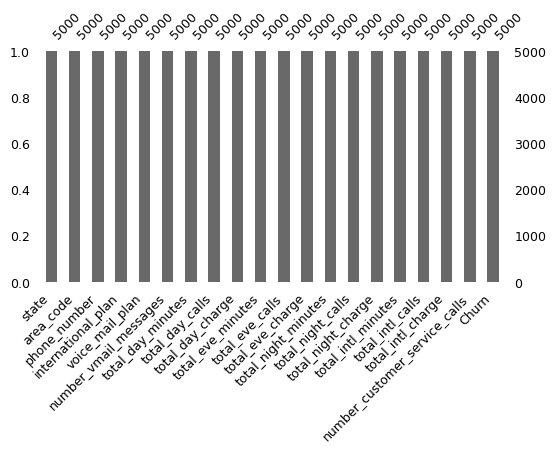

----------------------------------------------------------------------------------------------------
Visualization of the null values pattern:


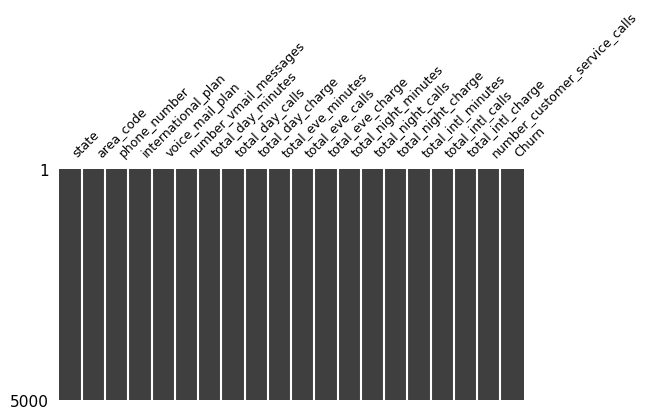

----------------------------------------------------------------------------------------------------


In [897]:
# nulls exploration
fpf.nulls_exploration(df)

In [898]:
# duplicates exploration
# each row corresponds to a single customer, therefore, phone numbers should be unique
df['phone_number'].duplicated().sum()

np.int64(0)

## 4. EDA 

In [899]:
df.head()

,state,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,Churn
0,KS,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


### Checking class balance

In [900]:
df['Churn'].value_counts(normalize=True)

Churn
False    0.8586
True     0.1414
Name: proportion, dtype: float64

### Churn rate by state

In [901]:
# do some states have significantly higher churn rates than others?
churn_rate_by_state = df.groupby('state').Churn.agg(['count','sum'])

In [902]:
churn_rate_by_state['churn rate'] = churn_rate_by_state['sum'] / churn_rate_by_state['count']
churn_rate_by_state = churn_rate_by_state.drop(['count', 'sum'], axis=1)
churn_rate_by_state = churn_rate_by_state.sort_values(by='churn rate', ascending=False)

<Axes: ylabel='churn rate'>

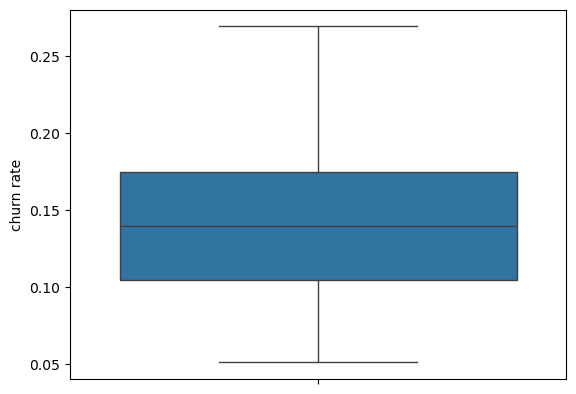

In [903]:
sns.boxplot(data=churn_rate_by_state, y='churn rate')

### Churn rate by international plan

In [904]:
df_international_churn = df.groupby('international_plan').Churn.agg(['count','sum'])
df_international_churn['churn rate'] = df_international_churn['sum']/df_international_churn['count']

<Axes: xlabel='international_plan', ylabel='churn rate'>

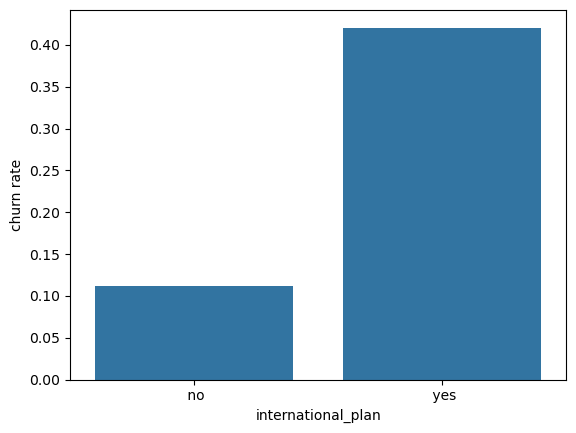

In [905]:
sns.barplot(data=df_international_churn, x='international_plan', y='churn rate')

### Churn rate by voice mail plan

In [906]:
df_voicemail_churn = df.groupby('voice_mail_plan').Churn.agg(['count','sum'])
df_voicemail_churn['churn rate'] = df_voicemail_churn['sum']/df_voicemail_churn['count']

<Axes: xlabel='voice_mail_plan', ylabel='churn rate'>

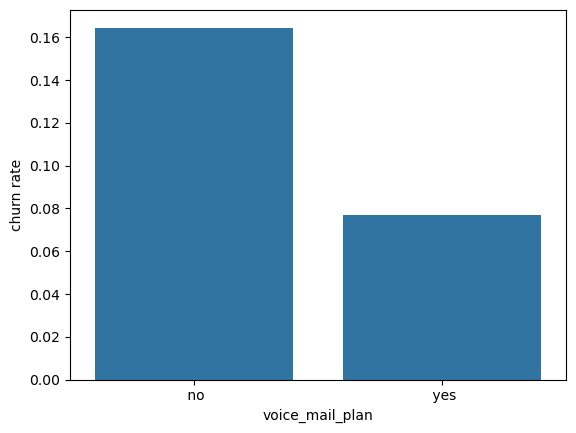

In [907]:
sns.barplot(data=df_voicemail_churn, x='voice_mail_plan', y='churn rate')

### Churn rate by number of customer service calls

In [908]:
df_cscalls_churn = df.groupby('number_customer_service_calls').Churn.agg(['count','sum'])
df_cscalls_churn['churn rate'] = df_cscalls_churn['sum']/df_cscalls_churn['count']

<Axes: xlabel='number_customer_service_calls', ylabel='churn rate'>

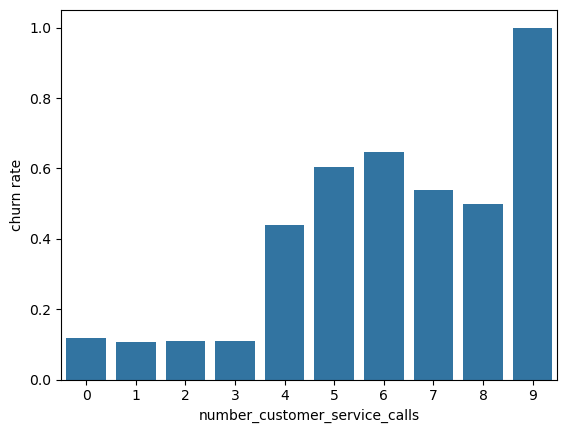

In [909]:
sns.barplot(data=df_cscalls_churn, x='number_customer_service_calls', y='churn rate')

## 5. ML Model

In [910]:
# we use a logistic regression model -> classification problem based on probabilities
# what columns do we use?
# what hyperparameters do we have to tune?
# what accuracy measure do we use?

### Feature selection

In [911]:
# we don't need these columns
drop_columns = ['area_code', 'phone_number']
df = df.drop(columns=drop_columns)

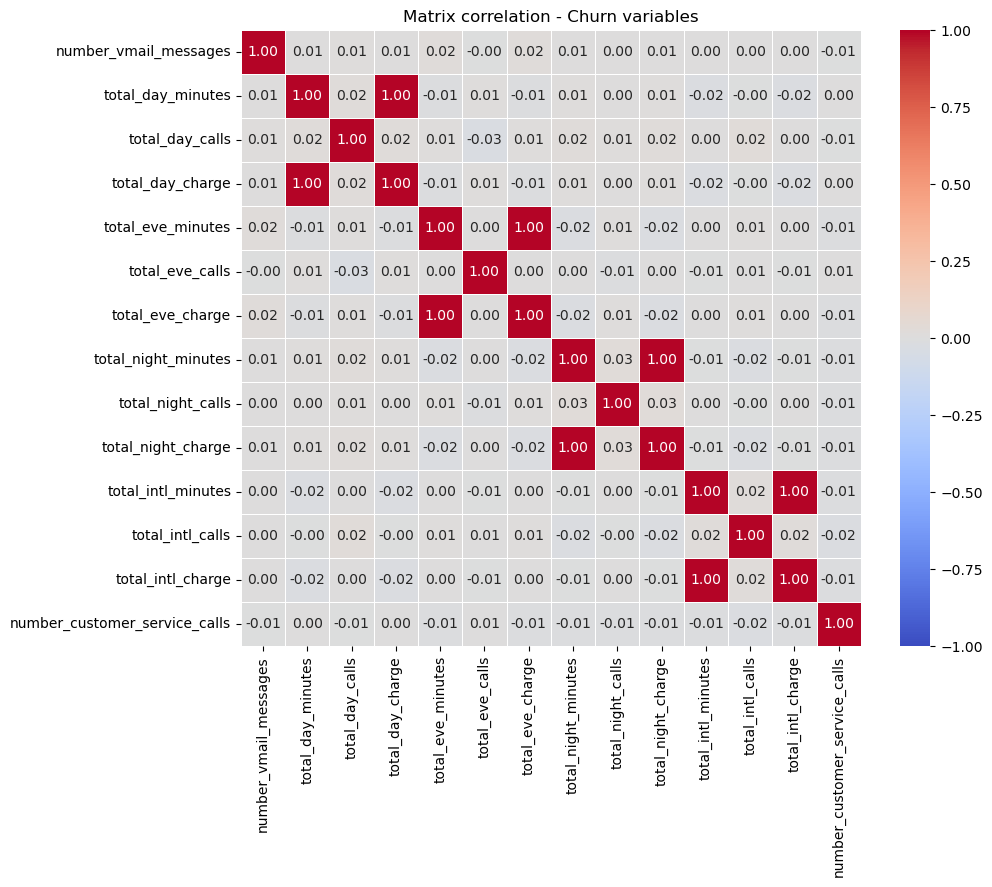

In [912]:
df_numeric = df.select_dtypes('number').copy()
corr_matrix = df_numeric.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True, 
    cmap="coolwarm",
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Matrix correlation - Churn variables")

plt.show()

In [913]:
# to avoid multicolinearity we drop the following columns:
columns_to_drop = ['total_day_minutes', 'total_eve_minutes', 'total_night_minutes', 'total_intl_minutes']
df = df.drop(columns=columns_to_drop)

### Preprocessing

In [914]:
categorical_cols = ['state', 'international_plan', 'voice_mail_plan']
numeric_cols = df.select_dtypes('number').columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),categorical_cols),
        ('num', StandardScaler(with_mean=False), numeric_cols)
    ]
)

### Train-test split

In [915]:
x = df[df.columns.drop('Churn')]
y = df['Churn']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Model and hyperparameter tunning

In [ ]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = LogisticRegressionCV(
    class_weight='balanced',
    scoring='average_precision',
    cv=cv_strategy,
    max_iter=2000,   # logistic regression on one-hot + scaled features can need
                      # more iterations than the sklearn default (100) to converge
    random_state=42,
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('logreg', logreg),
])

### Fit and get probabilities

In [917]:
pipeline.fit(x_train, y_train)

# .predict_proba returns two columns: P(class=False), P(class=True).
# We want the second one — the probability of churning — for both ranking
# customers and for threshold-independent metrics below.
y_proba = pipeline.predict_proba(x_test)[:, 1]
y_pred = pipeline.predict(x_test)  # hard 0/1 label at the default 0.5 threshold

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


### Evaluation

              precision    recall  f1-score   support

    No churn       0.95      0.78      0.86       859
       Churn       0.36      0.75      0.49       141

    accuracy                           0.78      1000
   macro avg       0.66      0.77      0.67      1000
weighted avg       0.87      0.78      0.81      1000



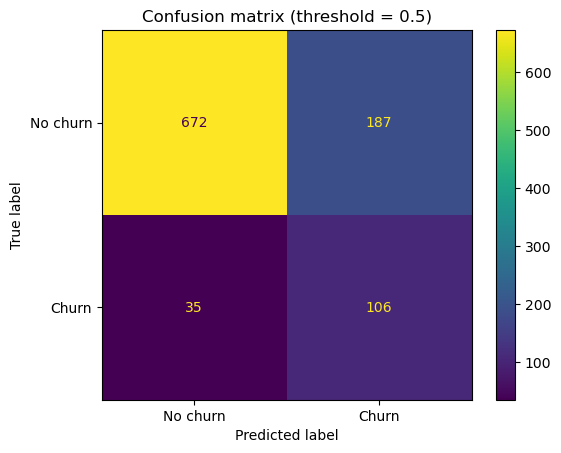

ROC-AUC: 0.826
Average Precision (PR-AUC): 0.456


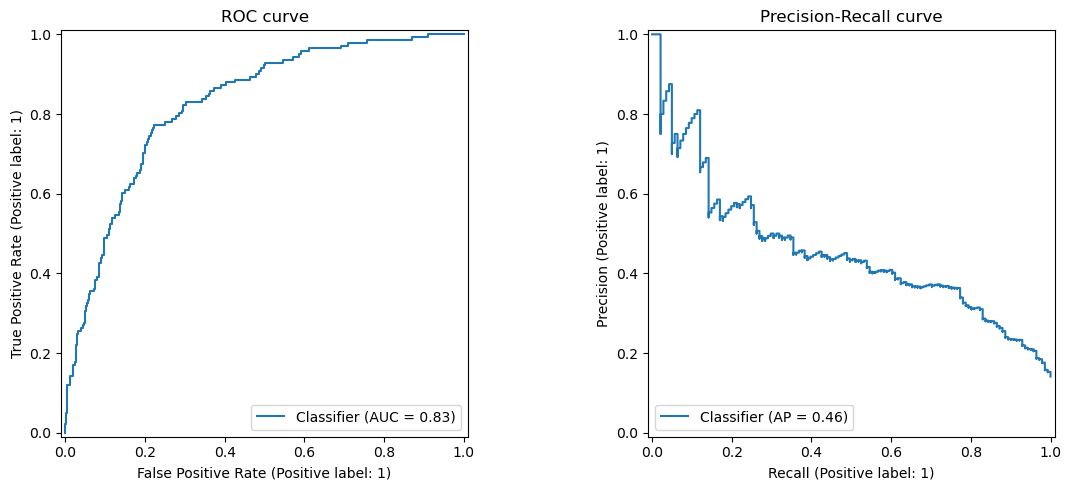

Naive baseline PR-AUC (~= churn rate): 0.141


In [918]:
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn','Churn'])
plt.title('Confusion matrix (threshold = 0.5)')
plt.show()

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Average Precision (PR-AUC): {pr_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('Precision-Recall curve')
plt.tight_layout()
plt.show()

# Naive baseline for context — this is your "vs. random" business question,
# computed here as a sanity check: a model with no skill has PR-AUC roughly
# equal to the churn rate itself (~0.14). Compare pr_auc above to that.
print(f"Naive baseline PR-AUC (~= churn rate): {y_test.mean():.3f}")

### Cross-validated validation

In [919]:
cv_results = cross_validate(
    pipeline, x_train, y_train,
    cv=cv_strategy,
    scoring=['roc_auc', 'average_precision', 'recall', 'precision'],
)

for metric in ['test_roc_auc', 'test_average_precision', 'test_recall', 'test_precision']:
    print(f"{metric}: {cv_results[metric].mean():.3f}  (+/- {cv_results[metric].std():.3f})")

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/opt/anaconda3/envs

test_roc_auc: 0.828  (+/- 0.024)
test_average_precision: 0.457  (+/- 0.045)
test_recall: 0.765  (+/- 0.067)
test_precision: 0.368  (+/- 0.010)


### Feature importance

/var/folders/6h/76s5lftj1d10282hykft0lm80000gn/T/ipykernel_63677/3385733045.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


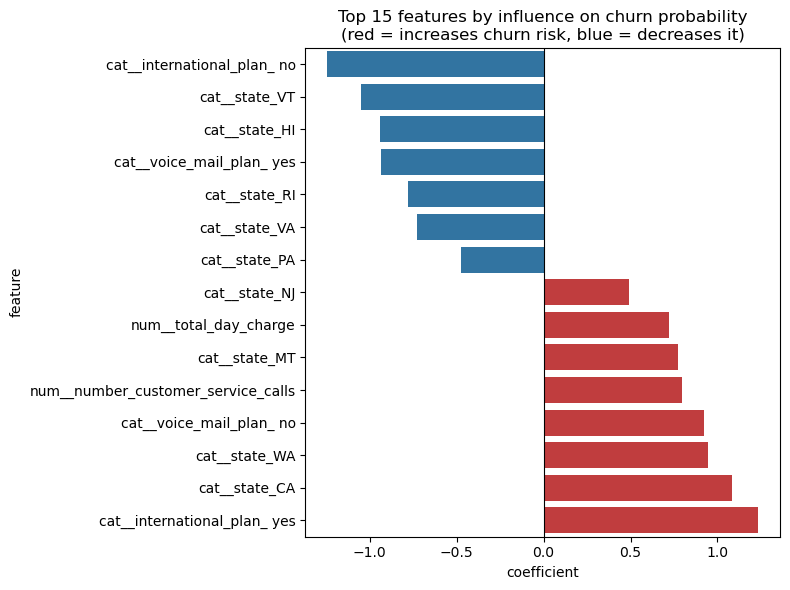

In [920]:
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
coefs = pipeline.named_steps['logreg'].coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
top_features = coef_df.sort_values('abs_coefficient', ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=top_features.sort_values('coefficient'),
    x='coefficient', y='feature',
    palette=['#d62728' if c > 0 else '#1f77b4' for c in top_features.sort_values('coefficient')['coefficient']]
)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 features by influence on churn probability\n(red = increases churn risk, blue = decreases it)')
plt.tight_layout()
plt.show()

### Ranking customers & comparison vs. random (bonus)

In [921]:
ranked = x_test.copy()
ranked['churn_probability'] = y_proba
ranked['actual_churn'] = y_test.values
ranked = ranked.sort_values('churn_probability', ascending=False)

top_500 = ranked.head(500)
churners_captured = top_500['actual_churn'].sum()
random_expected = 500 * y_test.mean()  # expected churners in a random sample of 500

print(f"Churners captured in top 500 (by model): {churners_captured}")
print(f"Expected churners in 500 random customers: {random_expected:.1f}")
print(f"Lift over random: {churners_captured / random_expected:.2f}x")

Churners captured in top 500 (by model): 125
Expected churners in 500 random customers: 70.5
Lift over random: 1.77x
